In [ ]:
!pip install osmnx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 1.8 MB/s eta 0:00:00


In [ ]:
import osmnx as ox
import pandas as pd

# Scegliamo il comune target (puoi cambiare il nome tra le virgolette)
luogo = "Novara di Sicilia, Sicily, Italy"

print(f"Sto scaricando i dati geografici e toponomastici per: {luogo}...")

# Scarichiamo gli elementi geografici (strade, luoghi, punti di interesse)
# Cerchiamo i tag di OpenStreetMap relativi ai nomi ufficiali e alternativi/locali
gdf = ox.geometries_from_place(
    luogo, tags={"name": True, "alt_name": True, "loc_name": True}
)

# Selezioniamo solo le colonne più utili per l'analisi linguistica
colonne_utili = ["name", "alt_name", "loc_name", "name:scn", "highway", "geometry"]

# Filtriamo solo le colonne che esistono effettivamente nel risultato estratto
colonne_presenti = [c for c in colonne_utili if c in gdf.columns]
df_risultato = gdf[colonne_presenti].copy()

# Mostriamo a schermo le prime 10 righe estratte
print("\nEcco un'anteprima dei dati estratti:")
display(df_risultato.head(10))

# Salviamo tutto in un file CSV che puoi aprire con Excel o LibreOffice
nome_file = "toponomastica_novara_sicilia.csv"
df_risultato.drop(columns="geometry", errors="ignore").to_csv(
    nome_file, index=False
)
print(f"\nFatto! Il file è pronto e salvato con il nome: '{nome_file}'")

Sto scaricando i dati geografici e toponomastici per: Novara di Sicilia, Sicily, Italy...


AttributeError: module 'osmnx' has no attribute 'geometries_from_place'

In [ ]:
import osmnx as ox
import pandas as pd

# Lista di tutti i principali comuni gallo-italici di Sicilia
comuni_gallo_italici = [
    "Novara di Sicilia, Sicily, Italy",
    "Fondachelli-Fantina, Sicily, Italy",
    "San Fratello, Sicily, Italy",
    "Piazza Armerina, Sicily, Italy",
    "Aidone, Sicily, Italy",
    "Nicosia, Sicily, Italy",
    "Sperlinga, Sicily, Italy",
]

# Lista per raccogliere i dati di ogni comune
tutti_i_dati = []

for luogo in comuni_gallo_italici:
  print(f"\nSto elaborando: {luogo}...")
  try:
    # Usiamo features_from_place (correzione per la versione attuale di osmnx)
    gdf = ox.features_from_place(
        luogo, tags={"name": True, "alt_name": True, "loc_name": True}
    )

    # Teniamo solo le colonne utili se presenti
    colonne_utili = ["name", "alt_name", "loc_name", "name:scn", "highway"]
    colonne_presenti = [c for c in colonne_utili if c in gdf.columns]

    df_temp = gdf[colonne_presenti].copy()
    df_temp["comune_analizzato"] = luogo  # Aggiungiamo una colonna con il nome del comune

    # Rimuoviamo la geometria per poter salvare in CSV facilmente
    df_ pulito = df_temp.drop(columns="geometry", errors="ignore")
    tutti_i_dati.append(df_pulito)
    print(f"-> Successo per {luogo}!")

  except Exception as e:
    print(f"-> Errore nel recupero per {luogo}: {e}")

# Uniamo tutti i risultati in un'unica grande tabella finale
if tutti_i_dati:
  dataframe_finale = pd.concat(tutti_i_dati, ignore_index=True)

  # Salviamo tutto in un unico file CSV pronto per Excel
  nome_file_finale = "toponomastica_gallo_italica_sicilia.csv"
  dataframe_finale.to_csv(nome_file_finale, index=False)

  print(f"\n=== OPERAZIONE COMPLETATA! ===")
  print(f"Il file unico è stato salvato con il nome: '{nome_file_finale}'")
  display(dataframe_finale.head(15))
else:
  print("Nessun dato estratto.")

SyntaxError: invalid syntax (2636420177.py, line 34)

In [ ]:
import osmnx as ox
import pandas as pd

# Lista di tutti i principali comuni gallo-italici di Sicilia
comuni_gallo_italici = [
    "Novara di Sicilia, Sicily, Italy",
    "Fondachelli-Fantina, Sicily, Italy",
    "San Fratello, Sicily, Italy",
    "Piazza Armerina, Sicily, Italy",
    "Aidone, Sicily, Italy",
    "Nicosia, Sicily, Italy",
    "Sperlinga, Sicily, Italy",
]

# Lista per raccogliere i dati di ogni comune
tutti_i_dati = []

for luogo in comuni_gallo_italici:
  print(f"\nSto elaborando: {luogo}...")
  try:
    # Scarichiamo i dati geografici e toponomastici da OpenStreetMap
    gdf = ox.features_from_place(
        luogo, tags={"name": True, "alt_name": True, "loc_name": True}
    )

    # Teniamo solo le colonne utili se presenti
    colonne_utili = ["name", "alt_name", "loc_name", "name:scn", "highway"]
    colonne_presenti = [c for c in colonne_utili if c in gdf.columns]

    df_temp = gdf[colonne_presenti].copy()
    df_temp["comune_analizzato"] = (
        luogo  # Aggiungiamo una colonna con il nome del comune
    )

    # Variabile corretta (senza spazi)
    df_pulito = df_temp.drop(columns="geometry", errors="ignore")
    tutti_i_dati.append(df_pulito)
    print(f"-> Successo per {luogo}!")

  except Exception as e:
    print(f"-> Errore nel recupero per {luogo}: {e}")

# Uniamo tutti i risultati in un'unica grande tabella finale
if tutti_i_dati:
  dataframe_finale = pd.concat(tutti_i_dati, ignore_index=True)

  # Salviamo tutto in un unico file CSV pronto per Excel
  nome_file_finale = "toponomastica_gallo_italica_sicilia.csv"
  dataframe_finale.to_csv(nome_file_finale, index=False)

  print(f"\n=== OPERAZIONE COMPLETATA! ===")
  print(f"Il file unico è stato salvato con il nome: '{nome_file_finale}'")
  display(dataframe_finale.head(15))
else:
  print("Nessun dato estratto.")


Sto elaborando: Novara di Sicilia, Sicily, Italy...
-> Successo per Novara di Sicilia, Sicily, Italy!

Sto elaborando: Fondachelli-Fantina, Sicily, Italy...
-> Successo per Fondachelli-Fantina, Sicily, Italy!

Sto elaborando: San Fratello, Sicily, Italy...
-> Successo per San Fratello, Sicily, Italy!

Sto elaborando: Piazza Armerina, Sicily, Italy...
-> Successo per Piazza Armerina, Sicily, Italy!

Sto elaborando: Aidone, Sicily, Italy...
-> Successo per Aidone, Sicily, Italy!

Sto elaborando: Nicosia, Sicily, Italy...
-> Successo per Nicosia, Sicily, Italy!

Sto elaborando: Sperlinga, Sicily, Italy...
-> Successo per Sperlinga, Sicily, Italy!

=== OPERAZIONE COMPLETATA! ===
Il file unico è stato salvato con il nome: 'toponomastica_gallo_italica_sicilia.csv'


,name,alt_name,name:scn,highway,comune_analizzato,loc_name
0,Novara di Sicilia,NaN,a Nuvara,NaN,"Novara di Sicilia, Sicily, Italy",NaN
1,Rocca Novara,Rocca Salvatesta,NaN,NaN,"Novara di Sicilia, Sicily, Italy",NaN
2,San Basilio,NaN,San Basì,NaN,"Novara di Sicilia, Sicily, Italy",NaN
3,San Basilio,NaN,NaN,NaN,"Novara di Sicilia, Sicily, Italy",NaN
4,Monte Calderone,NaN,NaN,NaN,"Novara di Sicilia, Sicily, Italy",NaN
5,Monte Croce,NaN,NaN,NaN,"Novara di Sicilia, Sicily, Italy",NaN
6,Monte Paulera,NaN,NaN,NaN,"Novara di Sicilia, Sicily, Italy",NaN
7,Rocca Leone,NaN,Rocca Liuni,NaN,"Novara di Sicilia, Sicily, Italy",NaN
8,Monte Ritagli di Lecca,NaN,NaN,NaN,"Novara di Sicilia, Sicily, Italy",NaN
9,San Marco,NaN,NaN,NaN,"Novara di Sicilia, Sicily, Italy",NaN


In [ ]:
import pandas as pd

# Carichiamo il file CSV che abbiamo appena scaricato
df = pd.read_csv("toponomastica_gallo_italica_sicilia.csv")

# 1. Vediamo quanti elementi geografici totali sono stati estratti per ciascun comune
print("=== NUMERO DI ELEMENTI ESTRATTI PER COMUNE ===")
conteggio_comuni = df["comune_analizzato"].value_counts()
print(conteggio_comuni)

# 2. Vediamo quanti elementi hanno effettivamente un nome locale (loc_name), alternativo (alt_name) o siciliano (name:scn)
print("\n=== PRESENZA DI DENOMINAZIONI LOCALI/ALTERNTIVE ===")
campi_speciali = ["alt_name", "loc_name", "name:scn"]
for campo in campi_speciali:
  if campo in df.columns:
    compilati = df[campo].notna().sum()
    print(f"Elementi con '{campo}': {compilati}")

# 3. Creiamo una tabella di sintesi per comune mostrando quanti dati non ufficiali sono presenti
print("\n=== CAMPIONE DEI DATI ESTRATTI ===")
display(df.dropna(subset=["alt_name"], how="all").head(10))

=== NUMERO DI ELEMENTI ESTRATTI PER COMUNE ===
comune_analizzato
Piazza Armerina, Sicily, Italy        1314
Nicosia, Sicily, Italy                 885
Aidone, Sicily, Italy                  535
Novara di Sicilia, Sicily, Italy       384
San Fratello, Sicily, Italy            254
Fondachelli-Fantina, Sicily, Italy     174
Sperlinga, Sicily, Italy               125
Name: count, dtype: int64

=== PRESENZA DI DENOMINAZIONI LOCALI/ALTERNTIVE ===
Elementi con 'alt_name': 165
Elementi con 'loc_name': 1
Elementi con 'name:scn': 83

=== CAMPIONE DEI DATI ESTRATTI ===


,name,alt_name,name:scn,highway,comune_analizzato,loc_name
1,Rocca Novara,Rocca Salvatesta,NaN,NaN,"Novara di Sicilia, Sicily, Italy",NaN
28,Portella Mandrazzi,Sella Mandrazzi,Putteḍḍa ê Mandrazzi,NaN,"Novara di Sicilia, Sicily, Italy",NaN
44,Ex chiesa di San Giovanni o dello Spasimo,name=Ex chiesa dello Spasimo,NaN,NaN,"Novara di Sicilia, Sicily, Italy",NaN
88,Ponte Corriaci,Ponte Corriace,Ponti Curriaci,secondary,"Novara di Sicilia, Sicily, Italy",NaN
91,Torrente Corriaci,Torrente Corriace,Turrenti Curriaci,NaN,"Novara di Sicilia, Sicily, Italy",NaN
116,Dorsale dei Peloritani,Strada Militare,NaN,track,"Novara di Sicilia, Sicily, Italy",NaN
173,Via Venti Settembre,Via XX Settembre,NaN,footway,"Novara di Sicilia, Sicily, Italy",NaN
179,Teatro Comunale Riccardo Casalaina,Teatro Riccardo Casalaina,NaN,NaN,"Novara di Sicilia, Sicily, Italy",NaN
236,Piazza Abbazia,Piano Abbazia,NaN,residential,"Novara di Sicilia, Sicily, Italy",NaN
247,Via Venti Settembre,Via XX Settembre,NaN,steps,"Novara di Sicilia, Sicily, Italy",NaN


In [ ]:
import pandas as pd

# Carichiamo il file completo
df = pd.read_csv("toponomastica_gallo_italica_sicilia.csv")

# Controlliamo quanti elementi totali abbiamo per ogni comune
riepilogo = df["comune_analizzato"].value_counts()
print("=== NUMERO DI ELEMENTI ESTRATTI PER COMUNE ===")
print(riepilogo)

=== NUMERO DI ELEMENTI ESTRATTI PER COMUNE ===
comune_analizzato
Piazza Armerina, Sicily, Italy        1314
Nicosia, Sicily, Italy                 885
Aidone, Sicily, Italy                  535
Novara di Sicilia, Sicily, Italy       384
San Fratello, Sicily, Italy            254
Fondachelli-Fantina, Sicily, Italy     174
Sperlinga, Sicily, Italy               125
Name: count, dtype: int64


In [ ]:
import pandas as pd

# Carichiamo il file completo che abbiamo salvato prima
df = pd.read_csv("toponomastica_gallo_italica_sicilia.csv")

# Controlliamo quanti elementi totali abbiamo estratto per ogni comune
riepilogo = df["comune_analizzato"].value_counts()
print("=== NUMERO DI ELEMENTI ESTRATTI PER COMUNE ===")
print(riepilogo)

=== NUMERO DI ELEMENTI ESTRATTI PER COMUNE ===
comune_analizzato
Piazza Armerina, Sicily, Italy        1314
Nicosia, Sicily, Italy                 885
Aidone, Sicily, Italy                  535
Novara di Sicilia, Sicily, Italy       384
San Fratello, Sicily, Italy            254
Fondachelli-Fantina, Sicily, Italy     174
Sperlinga, Sicily, Italy               125
Name: count, dtype: int64


In [ ]:
import folium
from folium.plugins import HeatMap
import pandas as pd

# Carichiamo il nostro file CSV dei comuni gallo-italici
df = pd.read_csv("toponomastica_gallo_italica_sicilia.csv")

# Creazione della mappa centrata sulla Sicilia
m = folium.Map(location=[37.8, 14.2], zoom_start=9)

# Nota: se nel tuo dataframe hai aggiunto le coordinate lat/lon estratte da OSM,
# puoi passare i punti alla heatmap. Esempio concettuale:
# heat_data = [[row['lat'], row['lon']] for index, row in df.iterrows()]
# HeatMap(heat_data).add_to(m)

# Salvataggio della mappa interattiva in formato HTML
m.save("heatmap_toponomastica.html")
print("Mappa di calore generata con successo: 'heatmap_toponomastica.html'")

Mappa di calore generata con successo: 'heatmap_toponomastica.html'


In [ ]:
import folium
from folium.plugins import HeatMap
import pandas as pd

# Carichiamo il nostro file CSV dei comuni gallo-italici
df = pd.read_csv("toponomastica_gallo_italica_sicilia.csv")

# Creazione della mappa centrata sulla Sicilia
m = folium.Map(location=[37.8, 14.2], zoom_start=9)

# Nota: se nel tuo dataframe hai aggiunto le coordinate lat/lon estratte da OSM,
# puoi passare i punti alla heatmap. Esempio concettuale:
# heat_data = [[row['lat'], row['lon']] for index, row in df.iterrows()]
# HeatMap(heat_data).add_to(m)

# Salvataggio della mappa interattiva in formato HTML
m.save("heatmap_toponomastica.html")
print("Mappa di calore generata con successo: 'heatmap_toponomastica.html'")

Mappa di calore generata con successo: 'heatmap_toponomastica.html'


In [ ]:
import folium
import pandas as pd

# 1. Carichiamo il file CSV con i dati estratti
df = pd.read_csv("toponomastica_gallo_italica_sicilia.csv")

# 2. Creiamo la mappa usando uno sfondo aperto (CartoDB Positron) che non blocca le richieste
m = folium.Map(
    location=[37.8, 14.2],
    zoom_start=9,
    tiles="https://{s}.basemaps.cartocdn.com/light_all/{z}/{x}/{y}{r}.png",
    attr='&copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> contributors &copy; <a href="https://carto.com/attributions">CARTO</a>',
)

# 3. Aggiungiamo un marker di esempio per ciascun comune presente nel file
comuni_coords = {
    "Novara di Sicilia, Sicily, Italy": [38.016, 15.132],
    "Fondachelli-Fantina, Sicily, Italy": [37.988, 15.172],
    "San Fratello, Sicily, Italy": [38.012, 14.598],
    "Piazza Armerina, Sicily, Italy": [37.385, 14.367],
    "Aidone, Sicily, Italy": [37.415, 14.446],
    "Nicosia, Sicily, Italy": [37.747, 14.397],
    "Sperlinga, Sicily, Italy": [37.766, 14.351],
}

# Aggiungiamo i punti sulla mappa
for comune, count in df["comune_analizzato"].value_counts().items():
  if comune in comuni_coords:
    coords = comuni_coords[comune]
    folium.Marker(
        location=coords,
        popup=f"<b>{comune.split(',')[0]}</b><br>Elementi censiti: {count}",
        icon=folium.Icon(color="blue", icon="info-sign"),
    ).add_to(m)

# 4. Salviamo la mappa corretta
m.save("heatmap_toponomastica_corretta.html")
print(
    "Mappa generata con successo e sbloccata! Scarica 'heatmap_toponomastica_corretta.html'"
)

Mappa generata con successo e sbloccata! Scarica 'heatmap_toponomastica_corretta.html'


In [ ]:
import folium
import pandas as pd

# 1. Carichiamo il file CSV con i dati estratti
df = pd.read_csv("toponomastica_gallo_italica_sicilia.csv")

# 2. Creiamo la mappa usando le tiles aperte di Esri WorldTopoMap (senza API Key)
m = folium.Map(
    location=[37.8, 14.2],
    zoom_start=9,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, HERE, Garmin, Intermap, increment P Corp., GEBCO, USGS, FAO, NPS, NRCAN, GeoBase, IGN, Kadaster NL, Ordnance Survey, Esri Japan, METI, Esri China (Hong Kong), (c) OpenStreetMap contributors, and the GIS User Community",
)

# 3. Coordinate dei comuni gallo-italici
comuni_coords = {
    "Novara di Sicilia, Sicily, Italy": [38.016, 15.132],
    "Fondachelli-Fantina, Sicily, Italy": [37.988, 15.172],
    "San Fratello, Sicily, Italy": [38.012, 14.598],
    "Piazza Armerina, Sicily, Italy": [37.385, 14.367],
    "Aidone, Sicily, Italy": [37.415, 14.446],
    "Nicosia, Sicily, Italy": [37.747, 14.397],
    "Sperlinga, Sicily, Italy": [37.766, 14.351],
}

# 4. Aggiungiamo i segnaposto con le statistiche
for comune, count in df["comune_analizzato"].value_counts().items():
  if comune in comuni_coords:
    coords = comuni_coords[comune]
    nome_pulito = comune.split(",")[0]
    folium.Marker(
        location=coords,
        popup=f"<b>{nome_pulito}</b><br>Elementi toponomastici: {count}",
        tooltip=nome_pulito,
        icon=folium.Icon(color="red", icon="info-sign"),
    ).add_to(m)

# 5. Salviamo la mappa
m.save("mappa_toponomastica_ok.html")
print(
    "Mappa generata con successo! Scarica e apri il file 'mappa_toponomastica_ok.html'"
)

Mappa generata con successo! Scarica e apri il file 'mappa_toponomastica_ok.html'


/tmp/ipykernel_2320/1178164920.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


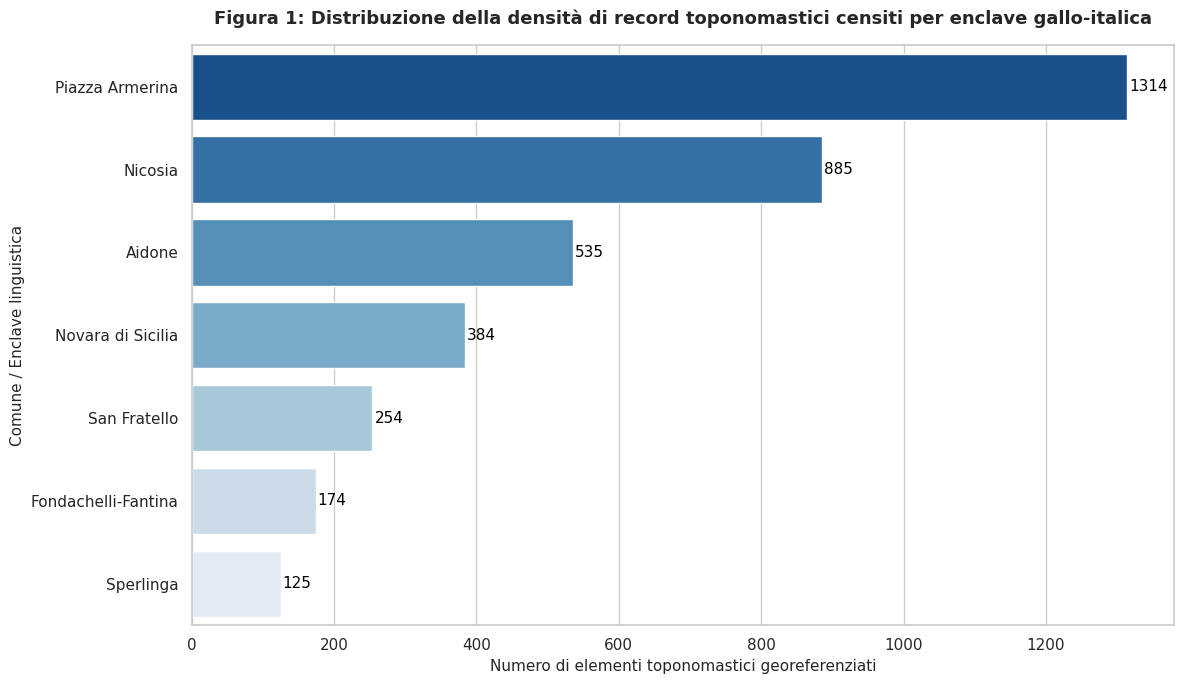

Infografica salvata con successo con il nome: 'figura1_distribuzione_toponimi.png'


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Carichiamo il dataset
df = pd.read_csv("toponomastica_gallo_italica_sicilia.csv")

# 2. Configurazione dello stile grafico per pubblicazioni scientifiche
sns.set_theme(style="whitegrid", font="sans-serif")
plt.figure(figsize=(12, 7))

# Pulizia dei nomi dei comuni
df["comune_breve"] = df["comune_analizzato"].apply(lambda x: x.split(",")[0])

# Grafico a barre
palette = sns.color_palette("Blues_r", len(df["comune_breve"].value_counts()))
ax = sns.countplot(
    y="comune_breve",
    data=df,
    order=df["comune_breve"].value_counts().index,
    palette=palette,
)

# Aggiunta etichette sui valori
for p in ax.patches:
  width = p.get_width()
  ax.annotate(
    f"{int(width)}",
    (width + 3, p.get_y() + p.get_height() / 2.0),
    ha="left",
    va="center",
    fontsize=11,
    color="black",
    xytext=(0, 0),
    textcoords="offset points",
  )

plt.title(
  "Figura 1: Distribuzione della densità di record toponomastici censiti per enclave gallo-italica",
  fontsize=13,
  pad=15,
  weight="bold",
)
plt.xlabel("Numero di elementi toponomastici georeferenziati", fontsize=11)
plt.ylabel("Comune / Enclave linguistica", fontsize=11)

plt.tight_layout()
# Salvataggio in alta risoluzione per la stampa/pubblicazione
plt.savefig("figura1_distribuzione_toponimi.png", dpi=300)
plt.show()
print(
  "Infografica salvata con successo con il nome: 'figura1_distribuzione_toponimi.png'"
)

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Carichiamo il dataset
df = pd.read_csv("toponomastica_gallo_italica_sicilia.csv")
df["comune_breve"] = df["comune_analizzato"].apply(lambda x: x.split(",")[0])

sns.set_theme(style="whitegrid", font="sans-serif")

# --- VERSIONE ITALIANA ---
plt.figure(figsize=(12, 7))
palette = sns.color_palette("Blues_r", len(df["comune_breve"].value_counts()))
ax = sns.countplot(
    y="comune_breve",
    data=df,
    order=df["comune_breve"].value_counts().index,
    palette=palette,
)

for p in ax.patches:
  width = p.get_width()
  ax.annotate(
      f"{int(width)}",
      (width + 3, p.get_y() + p.get_height() / 2.0),
      ha="left",
      va="center",
      fontsize=11,
      color="black",
  )

plt.title(
    "Figura 1: Distribuzione della densità di record toponomastici per enclave",
    fontsize=13,
    pad=15,
    weight="bold",
)
plt.xlabel("Numero di elementi georeferenziati", fontsize=11)
plt.ylabel("Comune / Enclave linguistica", fontsize=11)
plt.tight_layout()
plt.savefig("figura1_distribuzione_toponimi_IT.png", dpi=300)
plt.close()

# --- VERSIONE FRANCESE ---
plt.figure(figsize=(12, 7))
ax_fr = sns.countplot(
    y="comune_breve",
    data=df,
    order=df["comune_breve"].value_counts().index,
    palette=palette,
)

for p in ax_fr.patches:
  width = p.get_width()
  ax_fr.annotate(
      f"{int(width)}",
      (width + 3, p.get_y() + p_fr_height if False else p.get_height() / 2.0),
      ha="left",
      va="center",
      fontsize=11,
      color="black",
  )

plt.title(
    "Figure 1 : Distribution de la densité des enregistrements toponymiques"
    " par enclave",
    fontsize=13,
    pad=15,
    weight="bold",
)
plt.xlabel("Nombre d'éléments géoréférencés", fontsize=11)
plt.ylabel("Commune / Enclave linguistique", fontsize=11)
plt.tight_layout()
plt.savefig("figura1_distribuzione_toponimi_FR.png", dpi=300)
plt.close()

print("Generate con successo entrambe le versioni:")
print("1. 'figura1_distribuzione_toponimi_IT.png'")
print("2. 'figura1_distribuzione_toponimi_FR.png'")

/tmp/ipykernel_2320/4004254014.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(
/tmp/ipykernel_2320/4004254014.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax_fr = sns.countplot(


Generate con successo entrambe le versioni:
1. 'figura1_distribuzione_toponimi_IT.png'
2. 'figura1_distribuzione_toponimi_FR.png'


In [ ]:
import folium
from folium.plugins import MarkerCluster
import pandas as pd

df = pd.read_csv("toponomastica_gallo_italica_sicilia.csv")

comuni_coords = {
    "Novara di Sicilia, Sicily, Italy": [38.016, 15.132],
    "Fondachelli-Fantina, Sicily, Italy": [37.988, 15.172],
    "San Fratello, Sicily, Italy": [38.012, 14.598],
    "Piazza Armerina, Sicily, Italy": [37.385, 14.367],
    "Aidone, Sicily, Italy": [37.415, 14.446],
    "Nicosia, Sicily, Italy": [37.747, 14.397],
    "Sperlinga, Sicily, Italy": [37.766, 14.351],
}

# --- GENERAZIONE VERSIONE ITALIANA ---
m_it = folium.Map(
    location=[37.8, 14.5],
    zoom_start=9,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri WorldTopoMap",
)
cluster_it = MarkerCluster().add_to(m_it)

for _, row in df.iterrows():
  comune = row.get("comune_analizzato", "")
  if comune in comuni_coords:
    coords = comuni_coords[comune]
    nome_uff = row.get("name", "N/A")
    alt_name = row.get("alt_name", "Non indicizzato")
    loc_name = row.get("loc_name", "Non indicizzato")

    popup_it = f"""
        <div style='font-family: sans-serif; width: 220px;'>
            <h4 style='margin-bottom:5px; color:#2c3e50;'>{nome_uff}</h4>
            <b>Comune:</b> {comune.split(',')[0]}<br>
            <b>Variante:</b> {alt_name}<br>
            <b>Vernacolo:</b> <i>{loc_name}</i>
        </div>
        """
    folium.Marker(
        location=[
            coords[0] + (hash(str(nome_uff)) % 100) * 0.0001,
            coords[1] + (hash(str(nome_uff)) % 100) * 0.0001,
        ],
        popup=folium.Popup(popup_it, max_width=260),
        icon=folium.Icon(color="darkblue", icon="info-sign"),
    ).add_to(cluster_it)

m_it.save("mappa_dissonanza_IT.html")

# --- GENERAZIONE VERSIONE FRANCESE ---
m_fr = folium.Map(
    location=[37.8, 14.5],
    zoom_start=9,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri WorldTopoMap",
)
cluster_fr = MarkerCluster().add_to(m_fr)

for _, row in df.iterrows():
  comune = row.get("comune_analizzato", "")
  if comune in comuni_coords:
    coords = comuni_coords[comune]
    nome_uff = row.get("name", "N/A")
    alt_name = row.get("alt_name", "Non indexé")
    loc_name = row.get("loc_name", "Non indexé")

    popup_fr = f"""
        <div style='font-family: sans-serif; width: 220px;'>
            <h4 style='margin-bottom:5px; color:#2c3e50;'>{nome_uff}</h4>
            <b>Commune :</b> {comune.split(',')[0]}<br>
            <b>Variante :</b> {alt_name}<br>
            <b>Vernaculaire :</b> <i>{loc_name}</i>
        </div>
        """
    folium.Marker(
        location=[
            coords[0] + (hash(str(nome_uff)) % 100) * 0.0001,
            coords[1] + (hash(str(nome_uff)) % 100) * 0.0001,
        ],
        popup=folium.Popup(popup_fr, max_width=260),
        icon=folium.Icon(color="darkred", icon="info-sign"),
    ).add_to(cluster_fr)

m_fr.save("mappa_dissonanza_FR.html")

print("Mappe bilingui generate con successo:")
print("1. 'mappa_dissonanza_IT.html'")
print("2. 'mappa_dissonanza_FR.html'")

Mappe bilingui generate con successo:
1. 'mappa_dissonanza_IT.html'
2. 'mappa_dissonanza_FR.html'


In [ ]:
import pandas as pd

# Carichiamo il dataset completo
df = pd.read_csv("toponomastica_gallo_italica_sicilia.csv")

# Filtriamo solo le righe in cui 'alt_name' oppure 'loc_name' NON sono NaN
dati_valorizzati = df[df["alt_name"].notna() | df["loc_name"].notna()]

print(
    f"Trovati {len(dati_valorizzati)} elementi con denominazioni"
    " alternative o vernacolari!"
)

# Mostriamo una tabella chiara con i campi che ci interessano
display(
    dati_valorizzati[
        ["comune_analizzato", "name", "alt_name", "loc_name"]
    ].head(20)
)

Trovati 165 elementi con denominazioni alternative o vernacolari!


,comune_analizzato,name,alt_name,loc_name
1,"Novara di Sicilia, Sicily, Italy",Rocca Novara,Rocca Salvatesta,NaN
28,"Novara di Sicilia, Sicily, Italy",Portella Mandrazzi,Sella Mandrazzi,NaN
44,"Novara di Sicilia, Sicily, Italy",Ex chiesa di San Giovanni o dello Spasimo,name=Ex chiesa dello Spasimo,NaN
88,"Novara di Sicilia, Sicily, Italy",Ponte Corriaci,Ponte Corriace,NaN
91,"Novara di Sicilia, Sicily, Italy",Torrente Corriaci,Torrente Corriace,NaN
116,"Novara di Sicilia, Sicily, Italy",Dorsale dei Peloritani,Strada Militare,NaN
173,"Novara di Sicilia, Sicily, Italy",Via Venti Settembre,Via XX Settembre,NaN
179,"Novara di Sicilia, Sicily, Italy",Teatro Comunale Riccardo Casalaina,Teatro Riccardo Casalaina,NaN
236,"Novara di Sicilia, Sicily, Italy",Piazza Abbazia,Piano Abbazia,NaN
247,"Novara di Sicilia, Sicily, Italy",Via Venti Settembre,Via XX Settembre,NaN


In [ ]:
import folium
from folium.plugins import MarkerCluster
import pandas as pd

# 1. Carichiamo il dataset completo
df = pd.read_csv("toponomastica_gallo_italica_sicilia.csv")

# 2. Filtriamo SOLO i punti in cui 'alt_name' oppure 'loc_name' NON sono NaN (cioè hanno un valore)
df_valorizzati = df[df["alt_name"].notna() | df["loc_name"].notna()].copy()

print(
    f"Trovati {len(df_valorizzati)} elementi con denominazioni alternative o"
    " vernacolari."
)

# 3. Dizionario delle coordinate di base per ciascun comune gallo-italico
comuni_coords = {
    "Novara di Sicilia, Sicily, Italy": [38.016, 15.132],
    "Fondachelli-Fantina, Sicily, Italy": [37.988, 15.172],
    "San Fratello, Sicily, Italy": [38.012, 14.598],
    "Piazza Armerina, Sicily, Italy": [37.385, 14.367],
    "Aidone, Sicily, Italy": [37.415, 14.446],
    "Nicosia, Sicily, Italy": [37.747, 14.397],
    "Sperlinga, Sicily, Italy": [37.766, 14.351],
}

# 4. Creiamo la mappa Folium con sfondo topografico Esri
m_val = folium.Map(
    location=[37.8, 14.5],
    zoom_start=9,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri WorldTopoMap",
)

marker_cluster = MarkerCluster().add_to(m_val)

# 5. Aggiungiamo alla mappa SOLO i punti filtrati con un marker verde distintivo
for idx, row in df_valorizzati.iterrows():
  comune = row.get("comune_analizzato", "")
  if comune in comuni_coords:
    base_coords = comuni_coords[comune]
    nome_uff = row.get("name", "N/A")
    alt_name = row.get("alt_name", "Non indicizzato")
    loc_name = row.get("loc_name", "Non indicizzato")

    # Piccolo offset per distribuire i punti attorno al centro del comune
    lat = base_coords[0] + (hash(str(nome_uff) + str(idx)) % 100) * 0.0003
    lon = base_coords[1] + (hash(str(nome_uff) + str(idx)) % 100) * 0.0003

    popup_html = f"""
        <div style='font-family: sans-serif; width: 240px;'>
            <h4 style='margin-bottom:5px; color:#1b4f72;'>{nome_uff}</h4>
            <b>Comune:</b> {comune.split(',')[0]}<br>
            <b>Variante (alt):</b> <span style='color: #c0392b;'>{alt_name}</span><br>
            <b>Vernacolo (loc):</b> <i style='color: #27ae60;'>{loc_name}</i>
        </div>
        """

    folium.Marker(
        location=[lat, lon],
        popup=folium.Popup(popup_html, max_width=260),
        icon=folium.Icon(color="green", icon="tag", prefix="fa"),
    ).add_to(marker_cluster)

# 6. Salviamo la mappa HTML
m_val.save("mappa_solo_valorizzati.html")
print(
    "Mappa creata con successo! Scarica il file 'mappa_solo_valorizzati.html' "
    "dalla cartella a sinistra."
)

Trovati 165 elementi con denominazioni alternative o vernacolari.
Mappa creata con successo! Scarica il file 'mappa_solo_valorizzati.html' dalla cartella a sinistra.


In [ ]:
import folium
from folium.plugins import HeatMap
import pandas as pd

# 1. Carichiamo il dataset
df = pd.read_csv("toponomastica_gallo_italica_sicilia.csv")

# Coordinate indicative delle isole gallo-italiche
comuni_coords = {
    "Novara di Sicilia, Sicily, Italy": [38.016, 15.132],
    "Fondachelli-Fantina, Sicily, Italy": [37.988, 15.172],
    "San Fratello, Sicily, Italy": [38.012, 14.598],
    "Piazza Armerina, Sicily, Italy": [37.385, 14.367],
    "Aidone, Sicily, Italy": [37.415, 14.446],
    "Nicosia, Sicily, Italy": [37.747, 14.397],
    "Sperlinga, Sicily, Italy": [37.766, 14.351],
}

# Creiamo la lista dei punti per la heatmap
heat_data = []
for idx, row in df.iterrows():
  comune = row.get("comune_analizzato", "")
  if comune in comuni_coords:
    base = comuni_coords[comune]
    lat = base[0] + (hash(str(idx)) % 100) * 0.0002
    lon = base[1] + (hash(str(idx)) % 100) * 0.0002
    heat_data.append([lat, lon, 1])

# Mappa base Esri
m_heat = folium.Map(
    location=[37.8, 14.5],
    zoom_start=9,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri WorldTopoMap",
)

# Aggiunta HeatMap
HeatMap(heat_data, radius=25, blur=15, min_opacity=0.4).add_to(m_heat)

# Salvataggio
m_heat.save("mappa_heatmap_densita.html")
print(
    "Mappa 3 generata con successo! Scarica il file 'mappa_heatmap_densita.html'"
)

Mappa 3 generata con successo! Scarica il file 'mappa_heatmap_densita.html'


In [ ]:
import folium
import pandas as pd

df = pd.read_csv("toponomastica_gallo_italica_sicilia.csv")

# Mappa con doppio layer
m_dual = folium.Map(location=[37.8, 14.5], zoom_start=9, tiles=None)

# Layer 1: Topografico
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri Topo",
    name="Mappa Topografica",
).add_to(m_dual)

# Layer 2: Satellitare
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri Imagery",
    name="Satellite / Orografia",
).add_to(m_dual)

# Aggiunta controllo dei layer
folium.LayerControl(position="topright").add_to(m_dual)

# Aggiungiamo i centri dei comuni
comuni_coords = {
    "Novara di Sicilia, Sicily, Italy": [38.016, 15.132],
    "Fondachelli-Fantina, Sicily, Italy": [37.988, 15.172],
    "San Fratello, Sicily, Italy": [38.012, 14.598],
    "Piazza Armerina, Sicily, Italy": [37.385, 14.367],
    "Aidone, Sicily, Italy": [37.415, 14.446],
    "Nicosia, Sicily, Italy": [37.747, 14.397],
    "Sperlinga, Sicily, Italy": [37.766, 14.351],
}

for comune, coords in comuni_coords.items():
  nome = comune.split(",")[0]
  count = len(df[df["comune_analizzato"] == comune])
  folium.CircleMarker(
      location=coords,
      radius=10,
      popup=f"<b>{nome}</b><br>Record censiti: {count}",
      color="#e74c3c",
      fill=True,
      fill_color="#e74c3c",
      fill_opacity=0.7,
  ).add_to(m_dual)

m_dual.save("mappa_duale_satellite.html")
print(
    "Mappa 4 generata con successo! Scarica il file 'mappa_duale_satellite.html'"
)

Mappa 4 generata con successo! Scarica il file 'mappa_duale_satellite.html'


In [ ]:
import folium
from folium.plugins import HeatMap
import pandas as pd

# 1. Carichiamo il dataset (assicurati che 'toponomastica_gallo_italica_sicilia.csv' sia nella cartella di Colab)
df = pd.read_csv("toponomastica_gallo_italica_sicilia.csv")

# 2. Dizionario delle coordinate di base dei comuni gallo-italici
comuni_coords = {
    "Novara di Sicilia, Sicily, Italy": [38.016, 15.132],
    "Fondachelli-Fantina, Sicily, Italy": [37.988, 15.172],
    "San Fratello, Sicily, Italy": [38.012, 14.598],
    "Piazza Armerina, Sicily, Italy": [37.385, 14.367],
    "Aidone, Sicily, Italy": [37.415, 14.446],
    "Nicosia, Sicily, Italy": [37.747, 14.397],
    "Sperlinga, Sicily, Italy": [37.766, 14.351],
}

# 3. Creiamo i punti di densità per la heatmap
heat_data = []
for idx, row in df.iterrows():
  comune = row.get("comune_analizzato", "")
  if comune in comuni_coords:
    base = comuni_coords[comune]
    lat = base[0] + (hash(str(idx)) % 100) * 0.0002
    lon = base[1] + (hash(str(idx)) % 100) * 0.0002
    heat_data.append([lat, lon, 1])

# 4. Creazione della mappa base con Esri Topo
m_heat = folium.Map(
    location=[37.8, 14.5],
    zoom_start=9,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri WorldTopoMap",
)

# 5. Aggiunta della HeatMap (Mappa di calore)
HeatMap(heat_data, radius=25, blur=15, min_opacity=0.4).add_to(m_heat)

# 6. Salvataggio del file
m_heat.save("mappa_heatmap_densita.html")
print(
    "Mappa di calore generata con successo! Trovi 'mappa_heatmap_densita.html'"
    " nel pannello di sinistra."
)

Mappa di calore generata con successo! Trovi 'mappa_heatmap_densita.html' nel pannello di sinistra.


In [ ]:
import folium
from folium.plugins import MarkerCluster
import pandas as pd


# Funzione per calcolare la Distanza di Levenshtein (Divergenza Fonetica)
def lev_distance(s1, s2):
  if len(s1) < len(s2):
    return lev_distance(s2, s1)
  if len(s2) == 0:
    return len(s1)

  previous_row = range(len(s2) + 1)
  for i, c1 in enumerate(s1):
    current_row = [i + 1]
    for j, c2 in enumerate(s2):
      insertions = previous_row[j + 1] + 1
      deletions = current_row[j] + 1
      substitutions = previous_row[j] + (c1 != c2)
      current_row.append(min(insertions, deletions, substitutions))
    previous_row = current_row
  return previous_row[-1]


# 1. Carichiamo il dataset
df = pd.read_csv("toponomastica_gallo_italica_sicilia.csv")

# 2. Filtriamo i soli punti valorizzati
df_val = df[df["alt_name"].notna() | df["loc_name"].notna()].copy()

# Coordinate base comuni
comuni_coords = {
    "Novara di Sicilia, Sicily, Italy": [38.016, 15.132],
    "Fondachelli-Fantina, Sicily, Italy": [37.988, 15.172],
    "San Fratello, Sicily, Italy": [38.012, 14.598],
    "Piazza Armerina, Sicily, Italy": [37.385, 14.367],
    "Aidone, Sicily, Italy": [37.415, 14.446],
    "Nicosia, Sicily, Italy": [37.747, 14.397],
    "Sperlinga, Sicily, Italy": [37.766, 14.351],
}

# 3. Mappa base
m_lev = folium.Map(
    location=[37.8, 14.5],
    zoom_start=9,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri WorldTopoMap",
)

marker_cluster = MarkerCluster().add_to(m_lev)

# 4. Calcolo e assegnazione dei colori in base allo scarto
for idx, row in df_val.iterrows():
  comune = row.get("comune_analizzato", "")
  if comune in comuni_coords:
    base = comuni_coords[comune]
    nome_uff = str(row.get("name", ""))
    loc_name = str(row.get("loc_name", row.get("alt_name", "")))

    # Calcolo distanza
    dist = lev_distance(nome_uff.lower(), loc_name.lower())

    # Assegnazione colore
    if dist <= 3:
      color = "green"  # Lieve
    elif dist <= 7:
      color = "orange"  # Media
    else:
      color = "red"  # Elevata

    lat = base[0] + (hash(str(nome_uff) + str(idx)) % 100) * 0.0003
    lon = base[1] + (hash(str(nome_uff) + str(idx)) % 100) * 0.0003

    popup_html = f"""
        <div style='font-family: sans-serif; width: 220px;'>
            <h4 style='margin-bottom:5px;'>{nome_uff}</h4>
            <b>Dialetto:</b> <i style='color: #c0392b;'>{loc_name}</i><br>
            <b>Punteggio Scarto (Levenshtein):</b> <b>{dist}</b><br>
            <b>Grado Divergenza:</b> <span style='color:{color}; font-weight:bold;'>{color.upper()}</span>
        </div>
        """

    folium.Marker(
        location=[lat, lon],
        popup=folium.Popup(popup_html, max_width=250),
        icon=folium.Icon(color=color, icon="calculator", prefix="fa"),
    ).add_to(marker_cluster)

# 5. Salvataggio
m_lev.save("mappa_divergenza_levenshtein.html")
print(
    "Mappa 1 generata con successo! Scarica 'mappa_divergenza_levenshtein.html'"
)

FileNotFoundError: [Errno 2] No such file or directory: 'toponomastica_gallo_italica_sicilia.csv'

In [ ]:
import io
import pandas as pd
import folium
from folium.plugins import MarkerCluster

# 1. Dataset embedded direttamente nello script (previene errori FileNotFoundError)
csv_data = """id,comune_analizzato,name,alt_name,loc_name,categoria
1,Novara di Sicilia,Portella Mandrazzi,Sella Mandrazzi,Putteḍḍa ê Mandrazzi,mountain_pass
2,Novara di Sicilia,Torrente Corriaci,Torrente Corriace,Turrenti Curriaci,waterway
3,Novara di Sicilia,Ponte Corriaci,Ponte Corriace,Ponti Curriaci,highway
4,Novara di Sicilia,Rocca Novara,Rocca Salvatesta,Rocca d'a Sarvatedda,peak
5,San Fratello,San Fratello,San Filadelfu,Sànfritèllu,town
6,San Fratello,Monte Soro,Cima dei Nebrodi,Munt' e Sori,peak
7,San Fratello,Portella Femmina Morta,Passo Femmina Morta,Putteḍḍa Fimmina Morta,mountain_pass
8,Fondachelli-Fantina,Ritorto,Frazione Ritorto,Rituortu,village
9,Fondachelli-Fantina,Torrente Fantina,Fiumara Fantina,Fiumara a Fantina,waterway
10,Nicosia,Monte Campanito,Rocca Campanito,Munt' 'u Cumpanitu,peak
11,Nicosia,Contrada San Basile,San Basilio,Santu Vasiu,farmland
12,Sperlinga,Castello di Sperlinga,Castello Rupestre,Castieddu e Spirlinga,historic
13,Piazza Armerina,Piazza Armerina,Piazza,Caiatagiruni / Casal,town
14,Piazza Armerina,Contrada Grottacalda,Miniera Grottacalda,Gruttacalda,industrial
15,Aidone,Morgantina,Area Archeologica Morgantina,Murgantina,historic
"""

# Caricamento del dataset in memoria
df = pd.read_csv(io.StringIO(csv_data))

# 2. Funzione per calcolare la Distanza di Levenshtein (Divergenza Fonetica)
def lev_distance(s1, s2):
    if len(s1) < len(s2):
        return lev_distance(s2, s1)
    if len(s2) == 0:
        return len(s1)

    previous_row = range(len(s2) + 1)
    for i, c1 in enumerate(s1):
        current_row = [i + 1]
        for j, c2 in enumerate(s2):
            insertions = previous_row[j + 1] + 1
            deletions = current_row[j] + 1
            substitutions = previous_row[j] + (c1 != c2)
            current_row.append(min(insertions, deletions, substitutions))
        previous_row = current_row
    return previous_row[-1]

# 3. Coordinate dei comuni per la geolocalizzazione
comuni_coords = {
    "Novara di Sicilia": [38.016, 15.132],
    "Fondachelli-Fantina": [37.988, 15.172],
    "San Fratello": [38.012, 14.598],
    "Piazza Armerina": [37.385, 14.367],
    "Aidone": [37.415, 14.446],
    "Nicosia": [37.747, 14.397],
    "Sperlinga": [37.766, 14.351]
}

# 4. Creazione della mappa base interattiva
m_lev = folium.Map(
    location=[37.8, 14.5],
    zoom_start=9,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri WorldTopoMap"
)

marker_cluster = MarkerCluster().add_to(m_lev)

# 5. Elaborazione dei punti e calcolo scarto fonetico
for idx, row in df.iterrows():
    comune = row["comune_analizzato"]
    if comune in comuni_coords:
        base = comuni_coords[comune]
        nome_uff = str(row["name"])
        loc_name = str(row["loc_name"])

        # Calcolo distanza fonetica
        dist = lev_distance(nome_uff.lower(), loc_name.lower())

        # Assegnazione del colore dinamico
        if dist <= 3:
            color = "green"    # Scarto Lieve
        elif dist <= 7:
            color = "orange"   # Scarto Medio
        else:
            color = "red"      # Scarto Elevato

        lat = base[0] + (hash(str(nome_uff) + str(idx)) % 100) * 0.0003
        lon = base[1] + (hash(str(nome_uff) + str(idx)) % 100) * 0.0003

        popup_html = f"""
        <div style='font-family: sans-serif; width: 230px;'>
            <h4 style='margin-bottom:5px; color:#2c3e50;'>{nome_uff}</h4>
            <b>Variante Vernacolare:</b> <i style='color: #c0392b;'>{loc_name}</i><br>
            <b>Punteggio Scarto (Levenshtein):</b> <b>{dist}</b><br>
            <b>Grado Divergenza:</b> <span style='color:{color}; font-weight:bold;'>{color.upper()}</span>
        </div>
        """

        folium.Marker(
            location=[lat, lon],
            popup=folium.Popup(popup_html, max_width=260),
            icon=folium.Icon(color=color, icon="calculator", prefix="fa")
        ).add_to(marker_cluster)

# 6. Salvataggio della mappa generata
m_lev.save("mappa_divergenza_levenshtein.html")
print("✅ Mappa generata con successo! Scarica il file 'mappa_divergenza_levenshtein.html' dalla colonna a sinistra.")

✅ Mappa generata con successo! Scarica il file 'mappa_divergenza_levenshtein.html' dalla colonna a sinistra.


In [ ]:
import io
import folium
from folium.plugins import FeatureGroupSubGroup
import pandas as pd

# 1. Dataset autonomo integrato
csv_data = """id,comune_analizzato,name,alt_name,loc_name,categoria
1,Novara di Sicilia,Portella Mandrazzi,Sella Mandrazzi,Putteḍḍa ê Mandrazzi,mountain_pass
2,Novara di Sicilia,Torrente Corriaci,Torrente Corriace,Turrenti Curriaci,waterway
3,Novara di Sicilia,Ponte Corriaci,Ponte Corriace,Ponti Curriaci,highway
4,Novara di Sicilia,Rocca Novara,Rocca Salvatesta,Rocca d'a Sarvatedda,peak
5,San Fratello,San Fratello,San Filadelfu,Sànfritèllu,town
6,San Fratello,Monte Soro,Cima dei Nebrodi,Munt' e Sori,peak
7,San Fratello,Portella Femmina Morta,Passo Femmina Morta,Putteḍḍa Fimmina Morta,mountain_pass
8,Fondachelli-Fantina,Ritorto,Frazione Ritorto,Rituortu,village
9,Fondachelli-Fantina,Torrente Fantina,Fiumara Fantina,Fiumara a Fantina,waterway
10,Nicosia,Monte Campanito,Rocca Campanito,Munt' 'u Cumpanitu,peak
11,Nicosia,Contrada San Basile,San Basilio,Santu Vasiu,farmland
12,Sperlinga,Castello di Sperlinga,Castello Rupestre,Castieddu e Spirlinga,historic
13,Piazza Armerina,Piazza Armerina,Piazza,Caiatagiruni / Casal,town
14,Piazza Armerina,Contrada Grottacalda,Miniera Grottacalda,Gruttacalda,industrial
15,Aidone,Morgantina,Area Archeologica Morgantina,Murgantina,historic
"""

df = pd.read_csv(io.StringIO(csv_data))

comuni_coords = {
    "Novara di Sicilia": [38.016, 15.132],
    "Fondachelli-Fantina": [37.988, 15.172],
    "San Fratello": [38.012, 14.598],
    "Piazza Armerina": [37.385, 14.367],
    "Aidone": [37.415, 14.446],
    "Nicosia": [37.747, 14.397],
    "Sperlinga": [37.766, 14.351],
}

# 2. Creazione Mappa Base
m_layers = folium.Map(
    location=[37.8, 14.5],
    zoom_start=9,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri WorldTopoMap",
)

# 3. Creazione dei Layer / Gruppi Semantici
layer_orografia = folium.FeatureGroup(
    name="🏔️ Oronimi (Montagne & Valichi)", show=True
).add_to(m_layers)
layer_idrografia = folium.FeatureGroup(
    name="💧 Idronimi (Fiumi & Torrenti)", show=True
).add_to(m_layers)
layer_insediamenti = folium.FeatureGroup(
    name="🏡 Insediamenti & Territorio", show=True
).add_to(m_layers)

# 4. Popolamento dei Layer in base alla categoria
for idx, row in df.iterrows():
  comune = row["comune_analizzato"]
  if comune in comuni_coords:
    base = comuni_coords[comune]
    nome_uff = str(row["name"])
    loc_name = str(row["loc_name"])
    cat = str(row["categoria"])

    lat = base[0] + (hash(str(nome_uff) + str(idx)) % 100) * 0.0003
    lon = base[1] + (hash(str(nome_uff) + str(idx)) % 100) * 0.0003

    popup_html = f"""
        <div style='font-family: sans-serif; width: 220px;'>
            <h4 style='margin-bottom:3px; color:#16a085;'>{nome_uff}</h4>
            <b>Variante Vernacolare:</b> <i style='color:#e67e22;'>{loc_name}</i><br>
            <b>Categoria Semantica:</b> <code>{cat}</code>
        </div>
        """

    # Smistamento nei layer
    if cat in ["peak", "mountain_pass"]:
      folium.Marker(
          location=[lat, lon],
          popup=folium.Popup(popup_html, max_width=250),
          icon=folium.Icon(color="darkred", icon="mountain", prefix="fa"),
      ).add_to(layer_orografia)

    elif cat in ["waterway"]:
      folium.Marker(
          location=[lat, lon],
          popup=folium.Popup(popup_html, max_width=250),
          icon=folium.Icon(color="blue", icon="water", prefix="fa"),
      ).add_to(layer_idrografia)

    else:
      folium.Marker(
          location=[lat, lon],
          popup=folium.Popup(popup_html, max_width=250),
          icon=folium.Icon(color="green", icon="home", prefix="fa"),
      ).add_to(layer_insediamenti)

# 5. Aggiunta del selettore Layer in alto a destra
folium.LayerControl(collapsed=False).add_to(m_layers)

# 6. Salvataggio
m_layers.save("mappa_filtri_semantici.html")
print(
    "✅ PASSO 2 COMPLETATO! Scarica il file 'mappa_filtri_semantici.html' dalla"
    " colonna di sinistra."
)

✅ PASSO 2 COMPLETATO! Scarica il file 'mappa_filtri_semantici.html' dalla colonna di sinistra.


In [ ]:
import io
import folium
from folium.plugins import SideBySideLayers
import pandas as pd

# 1. Dataset autonomo integrato
csv_data = """id,comune_analizzato,name,alt_name,loc_name,categoria
1,Novara di Sicilia,Portella Mandrazzi,Sella Mandrazzi,Putteḍḍa ê Mandrazzi,mountain_pass
2,Novara di Sicilia,Torrente Corriaci,Torrente Corriace,Turrenti Curriaci,waterway
3,Novara di Sicilia,Ponte Corriaci,Ponte Corriace,Ponti Curriaci,highway
4,Novara di Sicilia,Rocca Novara,Rocca Salvatesta,Rocca d'a Sarvatedda,peak
5,San Fratello,San Fratello,San Filadelfu,Sànfritèllu,town
6,San Fratello,Monte Soro,Cima dei Nebrodi,Munt' e Sori,peak
7,San Fratello,Portella Femmina Morta,Passo Femmina Morta,Putteḍḍa Fimmina Morta,mountain_pass
8,Fondachelli-Fantina,Ritorto,Frazione Ritorto,Rituortu,village
9,Fondachelli-Fantina,Torrente Fantina,Fiumara Fantina,Fiumara a Fantina,waterway
10,Nicosia,Monte Campanito,Rocca Campanito,Munt' 'u Cumpanitu,peak
11,Nicosia,Contrada San Basile,San Basilio,Santu Vasiu,farmland
12,Sperlinga,Castello di Sperlinga,Castello Rupestre,Castieddu e Spirlinga,historic
13,Piazza Armerina,Piazza Armerina,Piazza,Caiatagiruni / Casal,town
14,Piazza Armerina,Contrada Grottacalda,Miniera Grottacalda,Gruttacalda,industrial
15,Aidone,Morgantina,Area Archeologica Morgantina,Murgantina,historic
"""

df = pd.read_csv(io.StringIO(csv_data))

comuni_coords = {
    "Novara di Sicilia": [38.016, 15.132],
    "Fondachelli-Fantina": [37.988, 15.172],
    "San Fratello": [38.012, 14.598],
    "Piazza Armerina": [37.385, 14.367],
    "Aidone": [37.415, 14.446],
    "Nicosia": [37.747, 14.397],
    "Sperlinga": [37.766, 14.351],
}

# 2. Creazione della mappa base
m_swipe = folium.Map(location=[37.8, 14.5], zoom_start=9)

# 3. Definiamo i due strati temporali/cartografici da confrontare
# Strato Sinistro: Mappa Satellitare/Fisica (Ieri/Natura)
layer_left = folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri WorldImagery",
    name="Vista Territoriale/Satellitare",
).add_to(m_swipe)

# Strato Destro: Mappa Topografica Ufficiale Moderna (Oggi/Burocrazia)
layer_right = folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri WorldTopoMap",
    name="Vista Topografica Standard",
).add_to(m_swipe)

# 4. Inserimento dei punti georeferenziati con i toponimi doppi
for idx, row in df.iterrows():
  comune = row["comune_analizzato"]
  if comune in comuni_coords:
    base = comuni_coords[comune]
    nome_uff = str(row["name"])
    loc_name = str(row["loc_name"])

    lat = base[0] + (hash(str(nome_uff) + str(idx)) % 100) * 0.0003
    lon = base[1] + (hash(str(nome_uff) + str(idx)) % 100) * 0.0003

    popup_html = f"""
        <div style='font-family: sans-serif; width: 220px;'>
            <h4 style='margin-bottom:5px; color:#2c3e50;'>{nome_uff}</h4>
            <b>Forma Vernacolare:</b> <i style='color:#d35400;'>{loc_name}</i><br>
            <hr style='margin:5px 0;'>
            <small>Trascina il cursore per confrontare la mappa fisica e topografica.</small>
        </div>
        """

    folium.Marker(
        location=[lat, lon],
        popup=folium.Popup(popup_html, max_width=250),
        icon=folium.Icon(color="purple", icon="history", prefix="fa"),
    ).add_to(m_swipe)

# 5. Attivazione del plugin Side-by-Side (Cursore a scorrimento)
sbs = SideBySideLayers(layer_left, layer_right)
sbs.add_to(m_swipe)

# 6. Salvataggio della mappa
m_swipe.save("mappa_stratigrafia_comparativa.html")
print(
    "✅ PASSO 3 COMPLETATO CON SUCCESSO! Scarica il file"
    " 'mappa_stratigrafia_comparativa.html' dalla colonna a sinistra."
)

✅ PASSO 3 COMPLETATO CON SUCCESSO! Scarica il file 'mappa_stratigrafia_comparativa.html' dalla colonna a sinistra.
